# Task B — XAA **No-FT** (Unified) — Frozen Fashion-CLIP image features

**Mục tiêu:** so sánh công bằng với nhánh **XAA FT** của Khanh. Biến thực nghiệm duy nhất: nguồn image features (Frozen pretrained vs Fine-tuned).

Đồng bộ hoàn toàn với `branch-b-b` (train) và `branch-b-c` (final evaluation):
split CSV thống nhất · XAA architecture · Multi-positive InfoNCE · training config · seed/init · FAISS `IndexFlatIP` · Recall@K · category aggregation.

Không có DVR / TME / Global Branch. Không fine-tune Fashion-CLIP. Chỉ train `XAAFusionModule`.

> Notebook này **chưa được chạy trên feature thật** khi tạo ra. Mọi con số chỉ xuất hiện sau khi bạn chạy trên Colab.

## 1. Environment Setup

In [1]:
import os, sys, json, time, random, math, subprocess, shutil, hashlib, warnings
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
try:
    import faiss
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "faiss-cpu"])
    import faiss

warnings.filterwarnings("ignore")
SEED = 42                                   # = B-B / B-C
def set_seed(s):                            # = B-B
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except Exception:
    IN_COLAB = False

def check(cond, msg):                       # = B-B: dừng ngay với thông báo rõ ràng
    if not cond:
        raise ValueError("CHECK FAILED: " + msg)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")
T_START = time.time()

Mounted at /content/drive
Device: cuda | Tesla T4


## 2. Configuration

Chỉ cần sửa các đường dẫn. Các feature phải là **feature pretrained gốc** do pipeline Tuấn tạo ra (notebook *Text Encoder* + *Image Encoder Task B*).

In [2]:
BASE        = "/content/drive/MyDrive/ĐATN/data/processed"
TEXT_DIR    = f"{BASE}/embeddings/text_features_taskb"       # text hidden/mask + master csv + *.npy ids
IMG_DIR     = f"{BASE}/embeddings/image_features_taskb"      # FROZEN reference hidden + target embeds
SPLIT_CSV_PATH = f"{TEXT_DIR}/FashionIQ_Task_B_Experiment_Split.csv"   # file split thống nhất (không sửa)
OUT_DIR     = f"{BASE}/models/xaa_no_ft_unified"

# tên file (chấp nhận cả tên cũ lẫn tên "-001" của notebook Khanh)
TEXT_HIDDEN_CANDIDATES = ["fashionclip_text_hidden_states.npy", "fashionclip_text_hidden_states-001.npy"]
TEXT_MASK_FILE = "fashionclip_text_attention_masks.npy"
REF_HIDDEN_FILE, REF_MAP_FILE = "reference_image_hidden_states.npy", "reference_id2idx.json"
TGT_EMBED_FILE, TGT_MAP_FILE  = "target_image_embeds.npy",         "target_id2idx.json"
IMG_META_FILE = "image_feature_metadata.json"                        # tuỳ chọn (No-FT có thể không có)

# copy .npy từ Drive về đĩa local Colab để mmap nhanh (không ảnh hưởng kết quả)
USE_LOCAL_CACHE = True
CACHE_DIR = "/content/xaa_noft_cache"

# ---- TUỲ CHỌN (để None nếu không dùng) ----
IMAGES_DIR = "/content/fashioniq_data/resized_images/resized_images"   # ảnh FashionIQ tải từ Kaggle (như notebook cũ); nếu thư mục chưa tồn tại thì spot-check/qualitative tự bỏ qua
FT_IMG_FEAT_DIR  = None      # thư mục image feature của nhánh FT (chỉ để ĐỐI CHIẾU, không dùng để train/eval)
FT_TEXT_FEAT_DIR = None      # thư mục text feature mà Khanh dùng (kiểm tra text giống hệt)
FT_RESULTS_DIR   = None      # thư mục output của branch-b-c (taskb_final_evaluation) để in bảng so sánh

EXPERIMENT_NAME = "XAA_NoFT_Unified"
BACKBONE_TYPE   = "No-FT"

# số lượng kỳ vọng từ file split thống nhất
EXPECTED = dict(rows=24016, train=16204, internal_val=1796, final_test=5916, excluded_final_overlap=100,
                final_unique_targets=5903)

os.makedirs(OUT_DIR, exist_ok=True)
BEST_CKPT = f"{OUT_DIR}/xaa_no_ft_best.pt"
LAST_CKPT = f"{OUT_DIR}/xaa_no_ft_last.pt"
HIST_JSON = f"{OUT_DIR}/training_history.json"
CFG_JSON  = f"{OUT_DIR}/training_config.json"

## 3. Load Unified Dataset Split

Đọc trực tiếp cột `experiment_split` (không `train_test_split` lại, không dùng official val để chọn checkpoint).
Giữ nguyên **original row index** (0..N-1) để khớp thứ tự file `.npy`.

In [3]:
check(os.path.exists(SPLIT_CSV_PATH), f"Không thấy split CSV: {SPLIT_CSV_PATH}")
df = pd.read_csv(SPLIT_CSV_PATH)
check(isinstance(df.index, pd.RangeIndex) and df.index.start == 0 and df.index.step == 1,
      "Split CSV phải giữ original row order (RangeIndex 0..N-1)")
for c in ["category", "reference_image_id", "target_image_id", "modification_text", "official_split", "experiment_split"]:
    check(c in df.columns, f"Thiếu cột {c}. Cột hiện có: {list(df.columns)}")
df["reference_image_id"] = df["reference_image_id"].astype(str).str.strip()
df["target_image_id"]    = df["target_image_id"].astype(str).str.strip()
df["category"]           = df["category"].astype(str).str.strip().str.lower()
df["experiment_split"]   = df["experiment_split"].astype(str).str.strip()

vc = df["experiment_split"].value_counts().to_dict()
print(vc)
check(len(df) == EXPECTED["rows"], f"rows={len(df)}")
check(set(vc) == {"train", "internal_val", "final_test", "excluded_final_overlap"}, f"experiment_split values={set(vc)}")
for k in ["train", "internal_val", "final_test", "excluded_final_overlap"]:
    check(vc[k] == EXPECTED[k], f"{k}={vc[k]} (expected {EXPECTED[k]})")

tgt_by = {k: set(df.loc[df.experiment_split == k, "target_image_id"]) for k in vc}
check(len(tgt_by["train"] & tgt_by["internal_val"]) == 0, "train ∩ internal_val có chung target ID")
check(len(tgt_by["train"] & tgt_by["final_test"]) == 0,   "train ∩ final_test có chung target ID (leakage)")
check(len(tgt_by["internal_val"] & tgt_by["final_test"]) == 0, "internal_val ∩ final_test có chung target ID (leakage)")
check(len(tgt_by["final_test"]) == EXPECTED["final_unique_targets"], f"final_test unique targets={len(tgt_by['final_test'])}")
check(set(df.loc[df.experiment_split.isin(["train", "internal_val"]), "official_split"]) == {"train"},
      "train/internal_val phải đều thuộc official train")
check(set(df.loc[df.experiment_split.isin(["final_test", "excluded_final_overlap"]), "official_split"]) == {"val"},
      "final_test/excluded phải thuộc official val")
ex = tgt_by["excluded_final_overlap"]
check(len(ex & (tgt_by["train"] | tgt_by["internal_val"])) == len(ex), "excluded_final_overlap phải là các target đã thấy ở train/internal_val")
print(f"[info] excluded_final_overlap: {len(ex)} target, KHÔNG nằm trong final evaluation.")

print(df.groupby(["experiment_split", "category"]).agg(n=("target_image_id", "size"), uniq_targets=("target_image_id", "nunique")))

{'train': 16204, 'final_test': 5916, 'internal_val': 1796, 'excluded_final_overlap': 100}
[info] excluded_final_overlap: 100 target, KHÔNG nằm trong final evaluation.
                                    n  uniq_targets
experiment_split       category                    
excluded_final_overlap shirt       51            51
                       toptee      49            49
final_test             dress     2017          2017
                       shirt     1987          1987
                       toptee    1912          1912
internal_val           dress      598           598
                       shirt      599           599
                       toptee     599           599
train                  dress     5387          5387
                       shirt     5389          5389
                       toptee    5428          5428


## 4. Load Frozen Fashion-CLIP Features

Dùng feature pretrained gốc. Không load FT checkpoint, không dùng FT feature. Shape được đọc từ file thực tế; chỉ các chiều **bắt buộc bởi kiến trúc** (50×768, 77×512, 512) mới được assert.

In [4]:
os.makedirs(CACHE_DIR, exist_ok=True)
def stage(path):
    check(os.path.exists(path), f"Không thấy file: {path}")
    if not USE_LOCAL_CACHE:
        return path
    dst = os.path.join(CACHE_DIR, os.path.basename(path))
    if not (os.path.exists(dst) and os.path.getsize(dst) == os.path.getsize(path)):
        print("copy ->", dst); shutil.copy(path, dst)
    return dst

text_hidden_path = next((f"{TEXT_DIR}/{n}" for n in TEXT_HIDDEN_CANDIDATES if os.path.exists(f"{TEXT_DIR}/{n}")), None)
check(text_hidden_path is not None, f"Không thấy text hidden states trong {TEXT_DIR}: {TEXT_HIDDEN_CANDIDATES}")

text_hidden = np.load(stage(text_hidden_path), mmap_mode="r")
text_mask   = np.load(stage(f"{TEXT_DIR}/{TEXT_MASK_FILE}"), mmap_mode="r")
ref_hidden  = np.load(stage(f"{IMG_DIR}/{REF_HIDDEN_FILE}"), mmap_mode="r")
tgt_embeds  = np.load(f"{IMG_DIR}/{TGT_EMBED_FILE}").astype(np.float32)
with open(f"{IMG_DIR}/{REF_MAP_FILE}") as f: reference_id2idx = json.load(f)
with open(f"{IMG_DIR}/{TGT_MAP_FILE}") as f: target_id2idx   = json.load(f)

print("text_hidden:", text_hidden.shape, "| text_mask:", text_mask.shape)
print("ref_hidden :", ref_hidden.shape,  "| tgt_embeds:", tgt_embeds.shape)
print("n_ref ids  :", len(reference_id2idx), "| n_tgt ids:", len(target_id2idx))

copy -> /content/xaa_noft_cache/fashionclip_text_hidden_states.npy
copy -> /content/xaa_noft_cache/fashionclip_text_attention_masks.npy
copy -> /content/xaa_noft_cache/reference_image_hidden_states.npy
text_hidden: (24016, 77, 512) | text_mask: (24016, 77)
ref_hidden : (16787, 50, 768) | tgt_embeds: (23742, 512)
n_ref ids  : 16787 | n_tgt ids: 23742


In [5]:
# ===== SANITY CHECKS: shape / mapping / NaN-Inf / alignment =====
def finite_chunked(arr, step=2000):
    return all(np.isfinite(np.asarray(arr[s:s+step])).all() for s in range(0, arr.shape[0], step))

check(text_hidden.shape == (len(df), 77, 512), f"text_hidden {text_hidden.shape} vs CSV rows {len(df)}")
check(text_mask.shape == (len(df), 77), f"text_mask {text_mask.shape}")
check(ref_hidden.ndim == 3 and ref_hidden.shape[1:] == (50, 768), f"ref_hidden shape {ref_hidden.shape}")
check(tgt_embeds.ndim == 2 and tgt_embeds.shape[1] == 512, f"tgt_embeds shape {tgt_embeds.shape}")

# mapping: phải là hoán vị đầy đủ của 0..N-1 và phủ toàn bộ ID trong CSV (kể cả excluded, như B-B)
for name, mp, n in [("reference", reference_id2idx, ref_hidden.shape[0]), ("target", target_id2idx, tgt_embeds.shape[0])]:
    check(len(mp) == n, f"len({name}_id2idx)={len(mp)} != {n}")
    check(sorted(mp.values()) == list(range(n)), f"{name}_id2idx không phải hoán vị 0..{n-1}")
check(all(i in reference_id2idx for i in df["reference_image_id"]), "Thiếu mapping reference")
check(all(i in target_id2idx    for i in df["target_image_id"]),    "Thiếu mapping target")
check(len(reference_id2idx) == df["reference_image_id"].nunique(), "reference map không khớp số reference unique trong CSV")
check(len(target_id2idx)    == df["target_image_id"].nunique(),    "target map không khớp số target unique trong CSV")

check(finite_chunked(text_hidden), "text_hidden có NaN/Inf")
check(finite_chunked(text_mask),   "text_mask có NaN/Inf")
check(finite_chunked(ref_hidden),  "ref_hidden có NaN/Inf")
check(np.isfinite(tgt_embeds).all(), "tgt_embeds có NaN/Inf")
_n = np.linalg.norm(tgt_embeds, axis=1)
check(abs(_n.mean() - 1.0) < 1e-3, f"target norm mean={_n.mean():.5f}")
check(set(np.unique(np.asarray(text_mask[:2000]))) <= {0.0, 1.0}, "text_mask không phải nhị phân")

# alignment CSV <-> thứ tự trích xuất embedding (các file *.npy do notebook Text Encoder lưu cùng thứ tự master csv)
def _npy(name):
    p = f"{TEXT_DIR}/{name}"
    return np.load(p, allow_pickle=True) if os.path.exists(p) else None
for fname, col in [("reference_image_ids.npy", "reference_image_id"), ("target_image_ids.npy", "target_image_id")]:
    a = _npy(fname)
    if a is None: print(f"[warn] không có {fname} -> bỏ qua kiểm tra này"); continue
    check(np.array_equal(np.array([str(x).strip() for x in a]), df[col].values), f"{fname} != thứ tự split CSV")
a = _npy("category.npy")
if a is not None: check(np.array_equal(np.array([str(x).strip().lower() for x in a]), df["category"].values), "category.npy != split CSV")
a = _npy("split.npy")
if a is not None: check(np.array_equal(np.array([str(x).strip().lower() for x in a]), df["official_split"].str.lower().values), "split.npy != official_split")
mp = f"{TEXT_DIR}/fashioniq_taskb_master.csv"
if os.path.exists(mp):
    m = pd.read_csv(mp)
    check(len(m) == len(df), "master csv khác số dòng với split csv")
    for c in ["reference_image_id", "target_image_id", "modification_text"]:
        check((m[c].astype(str).str.strip().values == df[c].astype(str).str.strip().values).all(), f"master csv cột {c} lệch thứ tự so với split csv")
    print("master CSV (nguồn text embedding) khớp từng dòng với split CSV.")
else:
    print("[warn] không có master csv -> chỉ kiểm tra qua *.npy ids")
print("OK. target norm mean = %.6f" % _n.mean())

# lưu mapping cố định để tái lập
with open(f"{OUT_DIR}/target_id2idx.json", "w") as f: json.dump(target_id2idx, f)
TGT_MAP_SHA = hashlib.sha256(json.dumps(target_id2idx, sort_keys=True).encode()).hexdigest()[:16]
print("target_id2idx sha256[:16] =", TGT_MAP_SHA)

master CSV (nguồn text embedding) khớp từng dòng với split CSV.
OK. target norm mean = 1.000000
target_id2idx sha256[:16] = 68808a8fbeee4998


### 4b. Guard: chắc chắn đây là feature **No-FT**

1. Không đường dẫn nào chứa dấu hiệu FT checkpoint. 2. Nếu có metadata thì không được có `checkpoint_filename`.
3. *(Tuỳ chọn)* spot-check: tính lại một số ảnh bằng `patrickjohncyh/fashion-clip` gốc và so với `.npy`.
4. *(Tuỳ chọn)* đối chiếu với FT: text phải **giống hệt**, image target phải **khác** (nếu giống hệt = đã lẫn feature).

In [6]:
FT_MARKERS = ["branch_a_ft", "xaa_branch_a_ft", "finetune", "fine_tune", "fine-tune"]
for p in [TEXT_DIR, IMG_DIR, text_hidden_path, SPLIT_CSV_PATH]:
    check(not any(mk in str(p).lower() for mk in FT_MARKERS), f"Đường dẫn có dấu hiệu FT: {p}")

meta_path = f"{IMG_DIR}/{IMG_META_FILE}"
if os.path.exists(meta_path):
    with open(meta_path) as f: img_meta = json.load(f)
    check(img_meta.get("base_model", "patrickjohncyh/fashion-clip") == "patrickjohncyh/fashion-clip", f"base_model={img_meta.get('base_model')}")
    check(not img_meta.get("checkpoint_filename"), f"Metadata có checkpoint_filename={img_meta.get('checkpoint_filename')} -> đây là feature FT!")
    print("image_feature_metadata:", img_meta)
else:
    img_meta = {}
    print("[info] không có image_feature_metadata.json (bình thường với pipeline No-FT); dựa vào spot-check/đối chiếu bên dưới.")

# --- (tuỳ chọn) spot-check bằng pretrained Fashion-CLIP gốc ---
SPOT = {"done": False}
if IMAGES_DIR and os.path.isdir(IMAGES_DIR):
    from transformers import CLIPModel, CLIPImageProcessor
    from PIL import Image
    _name = "patrickjohncyh/fashion-clip"
    _proc = CLIPImageProcessor.from_pretrained(_name)
    _clip = CLIPModel.from_pretrained(_name).to(device).eval()
    _rng = np.random.RandomState(0)
    _t_ids = list(_rng.choice(list(target_id2idx), 24, replace=False))
    _r_ids = list(_rng.choice(list(reference_id2idx), 12, replace=False))
    def _px(ids): return _proc(images=[Image.open(f"{IMAGES_DIR}/{i}.jpg").convert("RGB") for i in ids], return_tensors="pt")["pixel_values"].to(device)
    with torch.no_grad():
        _o = _clip.get_image_features(pixel_values=_px(_t_ids))
        _o = _o.pooler_output if hasattr(_o, "pooler_output") else _o
        _o = F.normalize(_o, dim=-1).cpu().numpy()
        _h = _clip.vision_model(pixel_values=_px(_r_ids)).last_hidden_state.cpu().numpy()
    _cos_t = (_o * tgt_embeds[[target_id2idx[i] for i in _t_ids]]).sum(1)
    _a = _h.reshape(len(_r_ids), -1); _b = np.stack([np.asarray(ref_hidden[reference_id2idx[i]]) for i in _r_ids]).reshape(len(_r_ids), -1)
    _cos_r = (_a * _b).sum(1) / (np.linalg.norm(_a, axis=1) * np.linalg.norm(_b, axis=1))
    print(f"spot-check target cos: min={_cos_t.min():.5f} | reference cos: min={_cos_r.min():.5f}")
    check(_cos_t.min() > 0.999 and _cos_r.min() > 0.999, "Feature trong .npy KHÔNG khớp pretrained Fashion-CLIP gốc!")
    SPOT = {"done": True, "target_cos_min": float(_cos_t.min()), "ref_cos_min": float(_cos_r.min())}
    del _clip; torch.cuda.empty_cache()
else:
    print("[info] IMAGES_DIR=None -> bỏ qua spot-check bằng model gốc.")

# --- (tuỳ chọn) đối chiếu với feature FT ---
if FT_TEXT_FEAT_DIR:
    _p = next((f"{FT_TEXT_FEAT_DIR}/{n}" for n in TEXT_HIDDEN_CANDIDATES if os.path.exists(f"{FT_TEXT_FEAT_DIR}/{n}")), None)
    check(_p is not None, "Không thấy text hidden của FT để đối chiếu")
    _ft = np.load(_p, mmap_mode="r"); check(_ft.shape == text_hidden.shape, "Text FT khác shape")
    _ix = np.random.RandomState(1).choice(len(df), 500, replace=False); _ix.sort()
    check(np.allclose(np.asarray(_ft[_ix]), np.asarray(text_hidden[_ix]), atol=1e-5), "Text features khác với bên FT (phải giống hệt, text encoder frozen ở cả hai)")
    print("Text features: GIỐNG bên FT (mẫu 500 dòng).")
if FT_IMG_FEAT_DIR:
    _ft_t = np.load(f"{FT_IMG_FEAT_DIR}/{TGT_EMBED_FILE}").astype(np.float32)
    with open(f"{FT_IMG_FEAT_DIR}/{TGT_MAP_FILE}") as f: _ft_map = json.load(f)
    check(_ft_t.shape == tgt_embeds.shape, "Target embeds FT khác shape")
    print("target_id2idx giống bên FT:", _ft_map == target_id2idx)
    _cos = (_ft_t[[_ft_map[i] for i in list(target_id2idx)[:2000]]] * tgt_embeds[[target_id2idx[i] for i in list(target_id2idx)[:2000]]]).sum(1)
    print(f"cos(FT, No-FT) trên 2000 target: mean={_cos.mean():.4f} min={_cos.min():.4f}")
    check(not np.allclose(_ft_t, tgt_embeds, atol=1e-6), "Target embeds No-FT TRÙNG feature FT -> đã lẫn feature!")

[info] không có image_feature_metadata.json (bình thường với pipeline No-FT); dựa vào spot-check/đối chiếu bên dưới.
[info] IMAGES_DIR=None -> bỏ qua spot-check bằng model gốc.


## 5. Dataset and DataLoader  (theo B-B, trả thêm `target_idx`)

In [7]:
class FusionTripletDataset(Dataset):
    def __init__(self, rows):
        self.rows = np.asarray(rows)                      # ORIGINAL row indices
        self.ref_ids = df["reference_image_id"].values
        self.tgt_ids = df["target_image_id"].values
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, i):
        r = int(self.rows[i])
        rid, tid = self.ref_ids[r], self.tgt_ids[r]
        t_idx = target_id2idx[tid]                         # mapping cố định
        return {
            "text_hidden":      torch.from_numpy(np.array(text_hidden[r], dtype=np.float32)),   # [77,512]
            "text_mask":        torch.from_numpy(np.array(text_mask[r],   dtype=np.float32)),   # [77]
            "reference_hidden": torch.from_numpy(np.array(ref_hidden[reference_id2idx[rid]], dtype=np.float32)),  # [50,768]
            "target_embed":     torch.from_numpy(tgt_embeds[t_idx]),                            # [512]
            "target_idx":       t_idx,
            "target_image_id":  tid,
        }

BATCH_SIZE, NUM_WORKERS = 128, 2
train_rows = np.where(df.experiment_split == "train")[0]
iv_rows    = np.where(df.experiment_split == "internal_val")[0]
check(len(train_rows) == EXPECTED["train"] and len(iv_rows) == EXPECTED["internal_val"], "số dòng train/internal_val sai")
train_ds, iv_ds = FusionTripletDataset(train_rows), FusionTripletDataset(iv_rows)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
                          num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"),
                          persistent_workers=NUM_WORKERS > 0)
iv_loader = DataLoader(iv_ds, batch_size=256, shuffle=False, num_workers=NUM_WORKERS,
                       pin_memory=(device.type == "cuda"))
b = next(iter(train_loader))
print({k: (tuple(v.shape) if torch.is_tensor(v) else type(v).__name__) for k, v in b.items()})
print("train batches:", len(train_loader), "| iv batches:", len(iv_loader))

{'text_hidden': (128, 77, 512), 'text_mask': (128, 77), 'reference_hidden': (128, 50, 768), 'target_embed': (128, 512), 'target_idx': (128,), 'target_image_id': 'list'}
train batches: 126 | iv batches: 8


## 6. XAA Fusion Module  (copy nguyên từ `branch-b-b` / `branch-b-c`)

`Linear(768→512) → LayerNorm → MHA(8 heads, dropout 0.1, Q=text, K=V=ref) → residual + LayerNorm → masked mean → L2`.

In [8]:
class XAAFusionModule(nn.Module):
    def __init__(self, text_dim=512, img_dim=768, embed_dim=512, num_heads=8, dropout=0.1):
        super().__init__()
        self.ref_proj = nn.Linear(img_dim, embed_dim)
        self.ref_ln   = nn.LayerNorm(embed_dim)
        self.attn = nn.MultiheadAttention(embed_dim=embed_dim, num_heads=num_heads,
                                          batch_first=True, dropout=dropout)
        self.out_ln = nn.LayerNorm(embed_dim)
        self.logit_scale = nn.Parameter(torch.tensor(math.log(1 / 0.07)))

    def forward(self, text_hidden, text_mask, reference_hidden):
        ref = self.ref_ln(self.ref_proj(reference_hidden))              # [B,50,512]
        att, _ = self.attn(query=text_hidden, key=ref, value=ref)       # [B,77,512]
        x = self.out_ln(text_hidden + att)                              # residual + LN
        m = text_mask.unsqueeze(-1)                                     # [B,77,1]
        pooled = (x * m).sum(1) / m.sum(1).clamp(min=1.0)               # masked mean
        return F.normalize(pooled, dim=-1)                              # [B,512]

def state_hash(m):
    h = hashlib.sha256()
    for k, v in m.state_dict().items():
        h.update(k.encode()); h.update(v.detach().cpu().numpy().tobytes())
    return h.hexdigest()[:16]

# kiến trúc kỳ vọng (từ B-B)
_EXPECTED_PARAMS = {"logit_scale": (), "ref_proj.weight": (512, 768), "ref_proj.bias": (512,),
    "ref_ln.weight": (512,), "ref_ln.bias": (512,), "attn.in_proj_weight": (1536, 512), "attn.in_proj_bias": (1536,),
    "attn.out_proj.weight": (512, 512), "attn.out_proj.bias": (512,), "out_ln.weight": (512,), "out_ln.bias": (512,)}
_m = XAAFusionModule()
check({k: tuple(v.shape) for k, v in _m.state_dict().items()} == _EXPECTED_PARAMS, "XAA param shapes khác B-B")
check(_m.attn.num_heads == 8 and abs(_m.attn.dropout - 0.1) < 1e-9, "XAA heads/dropout khác B-B")
print("Trainable params: %.2fM" % (sum(p.numel() for p in _m.parameters()) / 1e6)); del _m

Trainable params: 1.45M


## 7. Multi-positive InfoNCE Loss  (copy nguyên từ `branch-b-b`)

Positive mask theo `target_idx` (cùng target = positive, không bị coi là negative). Loss đối xứng query→target và target→query. Cập nhật `logit_scale` + clamp `[0, ln 100]` như B-B.

In [9]:
def multi_positive_infonce(comp, tgt, target_idx, logit_scale):
    comp = F.normalize(comp.float(), dim=-1)
    tgt  = F.normalize(tgt.float(),  dim=-1)
    logits = comp @ tgt.T * logit_scale.exp()                           # [B,B]
    pos = (target_idx[:, None] == target_idx[None, :]).float()          # positive_mask[i,j]
    def one_way(lg, p):
        logp = F.log_softmax(lg, dim=1)
        return (-(logp * p).sum(1) / p.sum(1).clamp(min=1.0)).mean()
    return 0.5 * (one_way(logits, pos) + one_way(logits.T, pos.T))      # comp->tgt & tgt->comp

_ti = torch.tensor([1, 1, 2, 3])
_l = multi_positive_infonce(torch.randn(4, 512), torch.randn(4, 512), _ti, torch.tensor(math.log(1 / 0.07)))
check(torch.isfinite(_l).item(), "loss self-test không finite")
# nếu mọi target khác nhau => phải trùng InfoNCE đối xứng chuẩn (diag labels)
_c, _t = torch.randn(8, 512), torch.randn(8, 512); _s = torch.tensor(math.log(1 / 0.07))
_lg = F.normalize(_c, dim=-1) @ F.normalize(_t, dim=-1).T * _s.exp(); _lab = torch.arange(8)
_std = 0.5 * (F.cross_entropy(_lg, _lab) + F.cross_entropy(_lg.T, _lab))
check(abs(float(multi_positive_infonce(_c, _t, torch.arange(8), _s)) - float(_std)) < 1e-5, "multi-positive != InfoNCE chuẩn khi không có duplicate")
print("loss self-test OK:", float(_l))

loss self-test OK: 1.4816992282867432


## 8. Training Configuration  (khớp B-B; các giá trị cứng bên dưới được **assert** để tránh sửa nhầm)

In [10]:
BB_REFERENCE = dict(batch_size=128, lr=3e-4, weight_decay=0.01, max_epochs=40, eval_every=2, patience=5,
                    early_stop_metric="R@10", grad_clip=1.0, warmup_ratio=0.05, seed=42, embed_dim=512,
                    num_heads=8, attn_dropout=0.1, logit_scale_init=math.log(1 / 0.07))
CONFIG = dict(batch_size=BATCH_SIZE, lr=3e-4, weight_decay=0.01, max_epochs=40, eval_every=2,
    patience=5,   # đếm theo số lần eval không cải thiện (5 eval = 10 epoch)
    early_stop_metric="R@10", grad_clip=1.0, warmup_ratio=0.05,
    seed=SEED, embed_dim=512, num_heads=8, attn_dropout=0.1, logit_scale_init=math.log(1 / 0.07),
    image_features="no_ft_frozen_fashion_clip", n_train=len(train_rows), n_internal_val=len(iv_rows),
    n_final_test=int((df.experiment_split == "final_test").sum()))
for k, v in BB_REFERENCE.items():
    check(CONFIG[k] == v, f"CONFIG[{k}]={CONFIG[k]} khác B-B ({v})")
LOGIT_MAX = math.log(100.0)
KS = (1, 5, 10, 50)

# ---- internal-val FAISS gallery (= B-B) ----
iv_target_ids = df.loc[iv_rows, "target_image_id"].values
gallery_ids = list(pd.unique(iv_target_ids))
gallery_pos = {tid: i for i, tid in enumerate(gallery_ids)}
gallery_embeds = np.ascontiguousarray(np.stack([tgt_embeds[target_id2idx[t]] for t in gallery_ids]).astype(np.float32))
faiss.normalize_L2(gallery_embeds)
gallery_index = faiss.IndexFlatIP(gallery_embeds.shape[1]); gallery_index.add(gallery_embeds)
iv_gt_pos = np.array([gallery_pos[t] for t in iv_target_ids])
print("Internal-val gallery:", gallery_embeds.shape, "| queries:", len(iv_gt_pos))

@torch.no_grad()
def evaluate(model):                                         # = B-B
    model.eval()
    qs = []
    for b in iv_loader:
        qs.append(model(b["text_hidden"].to(device), b["text_mask"].to(device),
                        b["reference_hidden"].to(device)).float().cpu().numpy())
    q = np.ascontiguousarray(np.concatenate(qs).astype(np.float32))
    faiss.normalize_L2(q)
    kmax = min(max(KS), gallery_index.ntotal)
    _, I = gallery_index.search(q, kmax)
    hit = (I == iv_gt_pos[:, None])
    return {f"R@{k}": float(hit[:, :min(k, kmax)].any(axis=1).mean() * 100) for k in KS}

# ---- model init: giống B-B (reset seed rồi khởi tạo ngay) ----
model = XAAFusionModule().to(device); print("Untrained:", evaluate(model))
set_seed(SEED); model = XAAFusionModule().to(device)
INIT_HASH = state_hash(model)
print("INIT HASH (so với notebook FT):", INIT_HASH)

optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG["lr"], weight_decay=CONFIG["weight_decay"])
total_steps  = CONFIG["max_epochs"] * len(train_loader)
warmup_steps = max(1, int(CONFIG["warmup_ratio"] * total_steps))
def lr_lambda(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    p = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1 + math.cos(math.pi * p))
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
CONFIG_SAVE = {**CONFIG, "init_hash": INIT_HASH, "target_id2idx_sha": TGT_MAP_SHA}
with open(CFG_JSON, "w") as f: json.dump(CONFIG_SAVE, f, indent=2)
print(CONFIG, "| total_steps:", total_steps, "| warmup:", warmup_steps)

Internal-val gallery: (1784, 512) | queries: 1796
Untrained: {'R@1': 0.11135857461024498, 'R@5': 0.3897550111358575, 'R@10': 0.8908685968819599, 'R@50': 2.783964365256125}
INIT HASH (so với notebook FT): e39dce75522c3ea3
{'batch_size': 128, 'lr': 0.0003, 'weight_decay': 0.01, 'max_epochs': 40, 'eval_every': 2, 'patience': 5, 'early_stop_metric': 'R@10', 'grad_clip': 1.0, 'warmup_ratio': 0.05, 'seed': 42, 'embed_dim': 512, 'num_heads': 8, 'attn_dropout': 0.1, 'logit_scale_init': 2.659260036932778, 'image_features': 'no_ft_frozen_fashion_clip', 'n_train': 16204, 'n_internal_val': 1796, 'n_final_test': 5916} | total_steps: 5040 | warmup: 252


## 9. Training and Validation  (checkpoint theo internal-val **R@10**)

In [11]:
history = {"train_loss": [], "eval": []}
best = {"R@10": -1.0, "epoch": 0, "metrics": None}
no_improve = 0
t_train = time.time()

for epoch in range(1, CONFIG["max_epochs"] + 1):
    model.train()
    run, n = 0.0, 0
    for b in tqdm(train_loader, desc=f"Epoch {epoch}", leave=False):
        th, tm = b["text_hidden"].to(device), b["text_mask"].to(device)
        rh, te = b["reference_hidden"].to(device), b["target_embed"].to(device)
        tidx = b["target_idx"].to(device)
        comp = model(th, tm, rh)
        loss = multi_positive_infonce(comp, te, tidx, model.logit_scale)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG["grad_clip"])
        optimizer.step(); scheduler.step()
        with torch.no_grad():
            model.logit_scale.clamp_(0, LOGIT_MAX)
        run += loss.item() * th.size(0); n += th.size(0)
    tl = run / n
    history["train_loss"].append(tl)
    msg = f"Epoch {epoch:02d} | loss {tl:.4f} | lr {scheduler.get_last_lr()[0]:.2e}"

    if epoch % CONFIG["eval_every"] == 0:
        m = evaluate(model)
        history["eval"].append({"epoch": epoch, **m})
        msg += " | " + " ".join(f"{k} {v:.2f}" for k, v in m.items())
        if m[CONFIG["early_stop_metric"]] > best["R@10"] + 1e-6:
            best = {"R@10": m["R@10"], "epoch": epoch, "metrics": m}
            torch.save({"model_state_dict": model.state_dict(), "optimizer_state_dict": optimizer.state_dict(),
                        "scheduler_state_dict": scheduler.state_dict(), "epoch": epoch,
                        "best_recall_at_10": m["R@10"], "config": CONFIG_SAVE,
                        "experiment_name": EXPERIMENT_NAME, "backbone_type": BACKBONE_TYPE}, BEST_CKPT)
            no_improve = 0; msg += "  <-- best"
        else:
            no_improve += 1
            if no_improve >= CONFIG["patience"]:
                print(msg); print(f"Early stopping tại epoch {epoch}"); break
    print(msg)

last_epoch = epoch
train_time = time.time() - t_train
print(f"Done. best epoch={best['epoch']} R@10={best['R@10']:.2f} | train time {train_time/60:.1f} min")

Epoch 1:   0%|          | 0/126 [00:00<?, ?it/s]

Epoch 01 | loss 4.2275 | lr 1.51e-04


Epoch 2:   0%|          | 0/126 [00:00<?, ?it/s]

Epoch 02 | loss 3.1378 | lr 3.00e-04 | R@1 8.63 R@5 24.33 R@10 33.96 R@50 63.47  <-- best


Epoch 3:   0%|          | 0/126 [00:00<?, ?it/s]

Epoch 03 | loss 2.3852 | lr 2.99e-04


... (30 outputs left out)

Epoch 19:   0%|          | 0/126 [00:00<?, ?it/s]

Epoch 19 | loss 0.4314 | lr 1.75e-04


Epoch 20:   0%|          | 0/126 [00:00<?, ?it/s]

Epoch 20 | loss 0.3891 | lr 1.62e-04 | R@1 21.38 R@5 43.04 R@10 54.01 R@50 78.79
Early stopping tại epoch 20
Done. best epoch=10 R@10=56.90 | train time 3.0 min


## 10. Save Best Checkpoint / History

In [12]:
torch.save({"model_state_dict": model.state_dict(), "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(), "epoch": last_epoch,
            "best_recall_at_10": best["R@10"], "config": CONFIG_SAVE,
            "experiment_name": EXPERIMENT_NAME, "backbone_type": BACKBONE_TYPE}, LAST_CKPT)
history["best"] = best; history["train_time_sec"] = train_time
with open(HIST_JSON, "w") as f: json.dump(history, f, indent=2)
check(os.path.exists(BEST_CKPT), "Chưa có best checkpoint (chưa có lần eval nào?)")
for fn in sorted(os.listdir(OUT_DIR)):
    print(f"{fn}  ({os.path.getsize(os.path.join(OUT_DIR, fn))/1e6:.2f} MB)")

target_id2idx.json  (0.49 MB)
training_config.json  (0.00 MB)
training_history.json  (0.00 MB)
xaa_no_ft_best.pt  (17.37 MB)
xaa_no_ft_last.pt  (17.37 MB)


## 11. Unified Final Evaluation  (copy logic từ `branch-b-c`)

Final test = đúng `experiment_split == "final_test"` (5.916 query, 5.903 target). `excluded_final_overlap` không tham gia.
- **Protocol A:** gallery = tất cả unique final target, `IndexFlatIP`, L2-normalize.
- **Protocol B:** gallery riêng từng category (dress/shirt/toptee), macro-average **không trọng số**.

In [13]:
# ---- load best checkpoint ----
ckpt = torch.load(BEST_CKPT, map_location="cpu", weights_only=False)
model = XAAFusionModule(); model.load_state_dict(ckpt["model_state_dict"], strict=True); model.to(device).eval()
ckpt_epoch, ckpt_best_r10 = ckpt["epoch"], ckpt["best_recall_at_10"]
del ckpt
print("Loaded:", BEST_CKPT, "| epoch", ckpt_epoch, "| internal R@10", ckpt_best_r10)

# ---- final-test queries (giữ ORIGINAL index) ----
test_indices = df.index[df["experiment_split"] == "final_test"].to_numpy()
df_test = df.loc[test_indices].reset_index(drop=True)
text_test = np.asarray(text_hidden[test_indices], dtype=np.float32)
mask_test = np.asarray(text_mask[test_indices],   dtype=np.float32)
check(len(df_test) == EXPECTED["final_test"] == len(text_test) == len(mask_test), "final_test lệch số lượng")
check(df_test["target_image_id"].isin(target_id2idx).all() and df_test["reference_image_id"].isin(reference_id2idx).all(), "final_test thiếu mapping")

class FinalTestDataset(Dataset):
    def __init__(self, d, t, m):
        self.d, self.t, self.m = d, t, m
        self.ref_ids, self.tgt_ids, self.cats = d["reference_image_id"].values, d["target_image_id"].values, d["category"].values
        self.mods = d["modification_text"].fillna("").astype(str).values
    def __len__(self): return len(self.d)
    def __getitem__(self, i):
        rid = self.ref_ids[i]
        return {"text_hidden": torch.from_numpy(self.t[i]), "text_mask": torch.from_numpy(self.m[i]),
                "reference_hidden": torch.from_numpy(np.array(ref_hidden[reference_id2idx[rid]], dtype=np.float32)),
                "reference_image_id": rid, "target_image_id": self.tgt_ids[i], "category": self.cats[i], "modification_text": self.mods[i]}
test_loader = DataLoader(FinalTestDataset(df_test, text_test, mask_test), batch_size=256, shuffle=False,
                         num_workers=2, pin_memory=(device.type == "cuda"))

q_list, q_ref_ids, q_tgt_ids, q_cats, q_mods = [], [], [], [], []
with torch.inference_mode():
    for b in tqdm(test_loader, desc="Encode queries"):
        e = model(b["text_hidden"].to(device), b["text_mask"].to(device), b["reference_hidden"].to(device))
        q_list.append(F.normalize(e.float(), dim=-1).cpu().numpy())
        q_ref_ids += list(b["reference_image_id"]); q_tgt_ids += list(b["target_image_id"])
        q_cats += list(b["category"]); q_mods += list(b["modification_text"])
query_embeddings = np.ascontiguousarray(np.concatenate(q_list).astype(np.float32))
q_ref_ids, q_tgt_ids, q_cats, q_mods = map(np.array, (q_ref_ids, q_tgt_ids, q_cats, q_mods))
check(query_embeddings.shape == (EXPECTED["final_test"], 512), f"query_embeddings {query_embeddings.shape}")
check(np.isfinite(query_embeddings).all(), "query embeddings có NaN/Inf")
check(abs(np.linalg.norm(query_embeddings, axis=1).mean() - 1.0) < 1e-3, "query norm != 1")
check(np.array_equal(q_tgt_ids, df_test["target_image_id"].values), "Thứ tự query bị lệch")

# ---- gallery / recall (= B-C) ----
TOPK = 50
def build_gallery(target_ids):
    ids = list(pd.unique(np.asarray(target_ids)))
    emb = np.ascontiguousarray(np.stack([tgt_embeds[target_id2idx[t]] for t in ids]).astype(np.float32)); faiss.normalize_L2(emb)
    idx = faiss.IndexFlatIP(emb.shape[1]); idx.add(emb)
    return ids, {t: i for i, t in enumerate(ids)}, idx
def search_recall(index, q, gt_pos, k=TOPK):
    k = min(k, index.ntotal)
    _, I = index.search(np.ascontiguousarray(q), k)
    hit = (I == np.asarray(gt_pos)[:, None])
    return {f"R@{kk}": float(hit[:, :min(kk, k)].any(axis=1).mean() * 100) for kk in KS}, I

# Protocol A
global_ids, global_pos, global_index = build_gallery(q_tgt_ids)
global_gt_pos = np.array([global_pos[t] for t in q_tgt_ids])
check(len(global_ids) == EXPECTED["final_unique_targets"] and global_index.ntotal == len(global_ids), f"global gallery={len(global_ids)}")
check(len(set(global_ids)) == len(global_ids), "Gallery có ID trùng")
check(set(q_tgt_ids) <= set(global_ids), "Có target của final query không nằm trong gallery")
global_metrics, global_I = search_recall(global_index, query_embeddings, global_gt_pos)

# Protocol B
CATS = ["dress", "shirt", "toptee"]
check(set(CATS) == set(q_cats), f"Category trong final_test: {set(q_cats)}")
rows = []
for c in CATS:
    mk = q_cats == c
    ids_c, pos_c, idx_c = build_gallery(q_tgt_ids[mk])
    rec, _ = search_recall(idx_c, query_embeddings[mk], [pos_c[t] for t in q_tgt_ids[mk]])
    rows.append({"Category": c, "Queries": int(mk.sum()), "Gallery_Size": len(ids_c), **rec})
cat_aware_df = pd.DataFrame(rows)
macro = {"Category": "Macro_Average", "Queries": int(cat_aware_df["Queries"].sum()), "Gallery_Size": int(cat_aware_df["Gallery_Size"].sum())}
macro.update({f"R@{k}": float(cat_aware_df[f"R@{k}"].mean()) for k in KS})      # macro, không trọng số
cat_aware_df = pd.concat([cat_aware_df, pd.DataFrame([macro])], ignore_index=True)

# phụ (như B-C): per-category recall trên gallery global
rows = []
for c in CATS:
    mk = q_cats == c; hit = (global_I[mk] == global_gt_pos[mk][:, None])
    rows.append({"Category": c, "Queries": int(mk.sum()), **{f"R@{k}": float(hit[:, :k].any(axis=1).mean() * 100) for k in KS}})
global_per_cat_df = pd.DataFrame(rows)

print("PROTOCOL A — Global targets-only gallery  | queries=%d | gallery=%d" % (len(query_embeddings), len(global_ids)))
print(pd.DataFrame([global_metrics]).round(2).to_string(index=False))
print("\nPROTOCOL B — Per-category targets-only gallery")
print(cat_aware_df.round(2).to_string(index=False))

Loaded: /content/drive/MyDrive/ĐATN/data/processed/models/xaa_no_ft_unified/xaa_no_ft_best.pt | epoch 10 | internal R@10 56.90423162583519


Encode queries:   0%|          | 0/24 [00:00<?, ?it/s]

PROTOCOL A — Global targets-only gallery  | queries=5916 | gallery=5903
 R@1   R@5  R@10  R@50
8.18 23.23 32.07 57.86

PROTOCOL B — Per-category targets-only gallery
     Category  Queries  Gallery_Size   R@1   R@5  R@10  R@50
        dress     2017          2017  8.13 22.71 30.74 57.51
        shirt     1987          1987  7.70 23.65 33.42 58.73
       toptee     1912          1912 10.25 27.72 37.81 65.79
Macro_Average     5916          5916  8.69 24.69 33.99 60.68


## 12. Results Summary → JSON / CSV, bảng và biểu đồ

In [14]:
macro_row = cat_aware_df[cat_aware_df.Category == "Macro_Average"].iloc[0]
result = {
    "experiment_name": EXPERIMENT_NAME, "backbone_type": BACKBONE_TYPE,
    "n_train": int(len(train_rows)), "n_internal_val": int(len(iv_rows)), "n_final_test": int(len(df_test)),
    "n_excluded_final_overlap": int((df.experiment_split == "excluded_final_overlap").sum()),
    "final_test_unique_targets": int(df_test.target_image_id.nunique()), "global_gallery_size": int(len(global_ids)),
    "best_epoch": int(ckpt_epoch), "last_epoch_run": int(last_epoch), "internal_val_recall_at_10": float(ckpt_best_r10),
    "global": {f"R@{k}": global_metrics[f"R@{k}"] for k in KS},
    "per_category": {r.Category: {f"R@{k}": float(r[f"R@{k}"]) for k in KS} | {"queries": int(r.Queries), "gallery_size": int(r.Gallery_Size)}
                     for _, r in cat_aware_df[cat_aware_df.Category.isin(CATS)].iterrows()},
    "macro": {f"R@{k}": float(macro_row[f"R@{k}"]) for k in KS},
    "global_per_category": {r.Category: {f"R@{k}": float(r[f"R@{k}"]) for k in KS} for _, r in global_per_cat_df.iterrows()},
    "provenance": {"init_hash": INIT_HASH, "target_id2idx_sha": TGT_MAP_SHA, "spot_check": SPOT, "seed": SEED,
                   "checkpoint": os.path.basename(BEST_CKPT), "unit": "percent"},
}
with open(f"{OUT_DIR}/final_evaluation_summary.json", "w") as f: json.dump(result, f, indent=2)
cat_aware_df.to_csv(f"{OUT_DIR}/category_aware_metrics.csv", index=False)
global_per_cat_df.to_csv(f"{OUT_DIR}/global_per_category_metrics.csv", index=False)
flat = {"experiment_name": EXPERIMENT_NAME, "backbone_type": BACKBONE_TYPE, "n_train": result["n_train"], "n_internal_val": result["n_internal_val"],
        "n_final_test": result["n_final_test"], "best_epoch": result["best_epoch"], "internal_val_R@10": result["internal_val_recall_at_10"]}
flat |= {f"global_R@{k}": result["global"][f"R@{k}"] for k in KS}
for c in CATS: flat |= {f"{c}_R@{k}": result["per_category"][c][f"R@{k}"] for k in KS}
flat |= {f"macro_R@{k}": result["macro"][f"R@{k}"] for k in KS}
pd.DataFrame([flat]).to_csv(f"{OUT_DIR}/final_evaluation_summary.csv", index=False)

print("=" * 72); print(f"FINAL TEST — {EXPERIMENT_NAME} ({BACKBONE_TYPE})"); print("=" * 72)
print(f"train / internal_val / final_test : {result['n_train']} / {result['n_internal_val']} / {result['n_final_test']}")
print(f"best epoch {result['best_epoch']} | internal-val R@10 {result['internal_val_recall_at_10']:.2f}")
tbl = pd.DataFrame({"Protocol A (global)": result["global"], **{f"B: {c}": result["per_category"][c] | {} for c in CATS}, "B: Macro": result["macro"]}).T
print(tbl[[f"R@{k}" for k in KS]].round(2).to_string())
print("\nSaved to:", OUT_DIR, "|", sorted(os.listdir(OUT_DIR)))

# ---- (tuỳ chọn) so sánh với nhánh FT của Khanh ----
if FT_RESULTS_DIR and os.path.exists(f"{FT_RESULTS_DIR}/category_aware_metrics.csv"):
    ft_cat = pd.read_csv(f"{FT_RESULTS_DIR}/category_aware_metrics.csv").set_index("Category")
    ft_sum = json.load(open(f"{FT_RESULTS_DIR}/final_evaluation_summary.json"))
    nf = cat_aware_df.set_index("Category")
    cmp_rows = [{"Setting": "Global", **{f"R@{k}": (global_metrics[f"R@{k}"], ft_sum[f"global_R@{k}"], ft_sum[f"global_R@{k}"] - global_metrics[f"R@{k}"]) for k in KS}}]
    for c in CATS + ["Macro_Average"]:
        cmp_rows.append({"Setting": c, **{f"R@{k}": (nf.loc[c, f"R@{k}"], ft_cat.loc[c, f"R@{k}"], ft_cat.loc[c, f"R@{k}"] - nf.loc[c, f"R@{k}"]) for k in KS}})
    print("\n(No-FT, FT, FT − No-FT):")
    print(pd.DataFrame(cmp_rows).to_string(index=False, float_format=lambda x: f"{x:.2f}"))

FINAL TEST — XAA_NoFT_Unified (No-FT)
train / internal_val / final_test : 16204 / 1796 / 5916
best epoch 10 | internal-val R@10 56.90
                       R@1    R@5   R@10   R@50
Protocol A (global)   8.18  23.23  32.07  57.86
B: dress              8.13  22.71  30.74  57.51
B: shirt              7.70  23.65  33.42  58.73
B: toptee            10.25  27.72  37.81  65.79
B: Macro              8.69  24.69  33.99  60.68

Saved to: /content/drive/MyDrive/ĐATN/data/processed/models/xaa_no_ft_unified | ['category_aware_metrics.csv', 'final_evaluation_summary.csv', 'final_evaluation_summary.json', 'global_per_category_metrics.csv', 'target_id2idx.json', 'training_config.json', 'training_history.json', 'xaa_no_ft_best.pt', 'xaa_no_ft_last.pt']


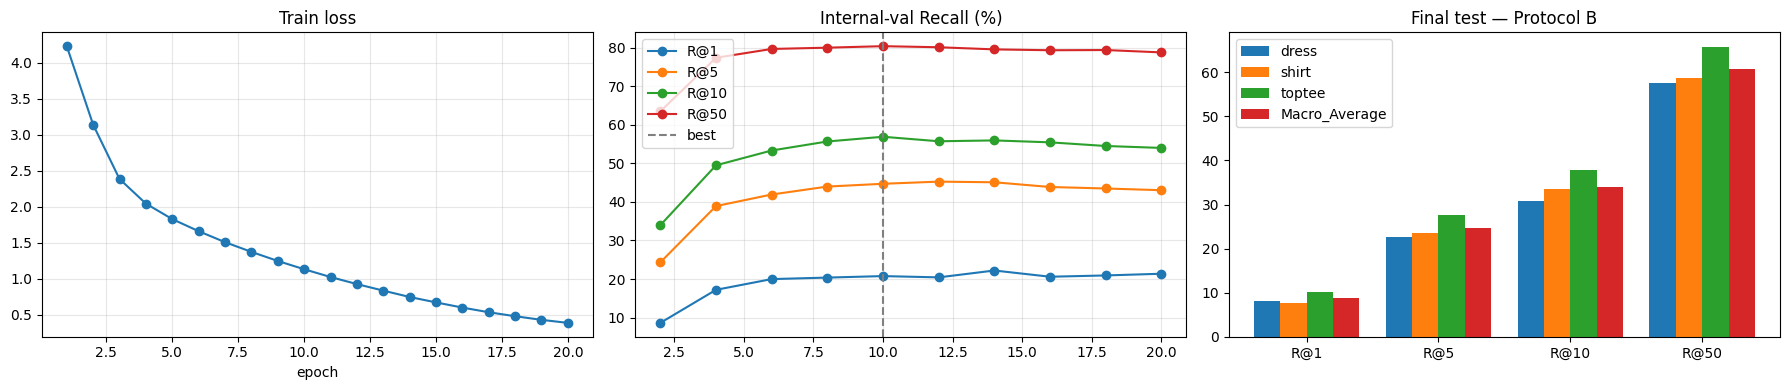

Total time: 6.9 min


In [15]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].plot(range(1, len(history["train_loss"]) + 1), history["train_loss"], marker="o"); ax[0].set_title("Train loss"); ax[0].set_xlabel("epoch"); ax[0].grid(alpha=.3)
ev_ep = [e["epoch"] for e in history["eval"]]
for k in KS: ax[1].plot(ev_ep, [e[f"R@{k}"] for e in history["eval"]], marker="o", label=f"R@{k}")
ax[1].axvline(best["epoch"], color="gray", ls="--", label="best"); ax[1].set_title("Internal-val Recall (%)"); ax[1].legend(); ax[1].grid(alpha=.3)
w = 0.2
for j, c in enumerate(CATS + ["Macro_Average"]):
    r = cat_aware_df[cat_aware_df.Category == c].iloc[0]
    ax[2].bar(np.arange(len(KS)) + j * w, [r[f"R@{k}"] for k in KS], w, label=c)
ax[2].set_xticks(np.arange(len(KS)) + 1.5 * w); ax[2].set_xticklabels([f"R@{k}" for k in KS]); ax[2].set_title("Final test — Protocol B"); ax[2].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/training_and_results.png", dpi=120); plt.show()

# qualitative (chỉ khi có ảnh)
if IMAGES_DIR and os.path.isdir(IMAGES_DIR):
    from PIL import Image
    rng = np.random.RandomState(SEED); pick = rng.choice(len(query_embeddings), 4, replace=False)
    fig, axes = plt.subplots(len(pick), 7, figsize=(21, 3 * len(pick)))
    for r_i, i in enumerate(pick):
        axes[r_i, 0].imshow(Image.open(f"{IMAGES_DIR}/{q_ref_ids[i]}.jpg").convert("RGB")); axes[r_i, 0].set_title("Reference", fontsize=9)
        axes[r_i, 1].text(0.5, 0.5, q_mods[i], wrap=True, ha="center", va="center", fontsize=8); axes[r_i, 1].set_title("Modification", fontsize=9)
        for k_i, j in enumerate(global_I[i][:5]):
            tid = global_ids[j]; ok = tid == q_tgt_ids[i]; a = axes[r_i, 2 + k_i]
            a.imshow(Image.open(f"{IMAGES_DIR}/{tid}.jpg").convert("RGB")); a.set_title(f"Top-{k_i+1}" + (" ✓" if ok else ""), color="green" if ok else "red", fontsize=8)
        for a in axes[r_i]: a.axis("off")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/qualitative_examples.png", dpi=120); plt.show()
print(f"Total time: {(time.time() - T_START)/60:.1f} min")